# Default Credit Card: Exploratory and Statistical Analysis

## Part I — Exploratory Data Analysis

### 1.1 Introduction and Initial Data Inspection

This case study examines the supplied credit card client dataset.
The analysis explores customer characteristics, credit-related
measurements, repayment information, and next-month default status.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display

# Read the supplied file without modifying the original data.
data_path = Path("DefaultCreditCard.csv")
df_raw = pd.read_csv(data_path)

# Use a separate copy for subsequent analysis.
df = df_raw.copy()

print("Number of observations:", df.shape[0])
print("Number of variables:", df.shape[1])

display(df.head())

Number of observations: 1000
Number of variables: 25


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,30,50000.0,1,1,2,26,0,0,0,0,...,17907.0,18375.0,11400.0,1500.0,1500.0,1000.0,1000.0,1600.0,0.0,0
1,64,50000.0,2,2,1,46,0,0,0,-2,...,0.0,0.0,0.0,1000.0,0.0,0.0,0.0,0.0,0.0,1
2,72,320000.0,1,2,2,29,2,2,2,2,...,58622.0,62307.0,63526.0,2500.0,2500.0,0.0,4800.0,2400.0,1600.0,1
3,113,280000.0,1,2,1,41,2,2,2,2,...,144401.0,152174.0,149415.0,6500.0,0.0,14254.0,14850.0,0.0,5000.0,0
4,133,420000.0,1,2,1,34,0,0,0,0,...,220951.0,210606.0,188108.0,9744.0,9553.0,7603.0,7830.0,7253.0,11326.0,0


In [2]:
# Inspect storage types, missing values, and distinct values.
data_check = pd.DataFrame({
    "Data type": df.dtypes.astype(str),
    "Missing values": df.isna().sum(),
    "Unique values": df.nunique(dropna=False)
})

display(data_check)

print("Total missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Duplicate IDs:", int(df["ID"].duplicated().sum()))

# Check that the outcome contains only the expected binary codes.
target = "default.payment.next.month"
assert df[target].isin([0, 1]).all(), "Unexpected default codes found."

default_summary = (
    df[target]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename_axis("Default code")
    .to_frame("Number of clients")
)

default_summary["Percentage (%)"] = (
    default_summary["Number of clients"] / len(df) * 100
)

display(default_summary.round(4))

,Data type,Missing values,Unique values
ID,int64,0,1000
LIMIT_BAL,float64,0,57
SEX,int64,0,2
EDUCATION,int64,0,6
MARRIAGE,int64,0,4
AGE,int64,0,45
PAY_0,int64,0,10
PAY_2,int64,0,10
PAY_3,int64,0,9
PAY_4,int64,0,8


Total missing values: 0
Duplicate rows: 0
Duplicate IDs: 0


,Number of clients,Percentage (%)
Default code,,
0,784,78.4
1,216,21.6


### 1.2 Data Quality and Variable Types

The supplied dataset contains 1,000 observations and 25 original variables. Each observation represents one credit card client. There are no missing values detected by pandas, no fully duplicated rows, and no duplicated client IDs.

The next-month default variable contains 216 defaults and 784 non-defaults, giving a sample default rate of 21.6%.

ID is an identifier rather than a numerical measurement. LIMIT_BAL, AGE, the bill amounts, and the payment amounts are quantitative variables. SEX, EDUCATION, MARRIAGE, and the default indicator are categorical variables, although they are stored as integers. The repayment-status variables are coded categories and should not automatically be treated as continuous measurements.

The absence of missing values does not guarantee that every code has a clearly documented meaning. Category codes will be checked before they are interpreted or recoded.

The original data are retained. No observations are removed merely because their values are large or because a bill amount is negative. Such values require investigation rather than automatic deletion.

### 1.3 Numerical Descriptive Statistics

The following table summarises credit limit, age, and the bill and payment amounts recorded in BILL_AMT1 and PAY_AMT1.

The mean and median describe the centre of each distribution. The sample standard deviation and quartiles describe its spread. ID and categorical codes are excluded from this numerical summary.

In [3]:
# Select quantitative variables for the descriptive summary.
numeric_columns = [
    "LIMIT_BAL",
    "AGE",
    "BILL_AMT1",
    "PAY_AMT1"
]

# describe() calculates the count, mean, sample standard deviation,
# minimum, quartiles, and maximum.
# .T puts variables in rows, making the table easier to read.
descriptive_stats = df[numeric_columns].describe().T

descriptive_stats = descriptive_stats.rename(columns={
    "count": "N",
    "mean": "Mean",
    "std": "SD",
    "min": "Minimum",
    "25%": "Q1",
    "50%": "Median",
    "75%": "Q3",
    "max": "Maximum"
})

display(descriptive_stats.round(4))

,N,Mean,SD,Minimum,Q1,Median,Q3,Maximum
LIMIT_BAL,1000.0,174080.000,132714.6065,10000.0,60000.00,150000.0,250000.00,680000.0
AGE,1000.0,35.412,9.4155,21.0,28.00,34.0,41.00,66.0
BILL_AMT1,1000.0,51341.698,74935.4060,-9095.0,2902.50,20952.5,68287.75,568532.0
PAY_AMT1,1000.0,5942.817,15732.8510,0.0,861.75,2100.0,5253.00,244500.0


#### Interpretation of the Numerical Summary

The mean credit limit is 174,080, compared with a median of 150,000.The higher mean suggests that larger credit limits pull the average upward. The distribution will be examined further using visualisation.

The mean age is 35.412 years and the median is 34 years. These figures describe all clients in the sample, not only those who default. The age profile of defaulting clients will be examined separately.

For BILL_AMT1, the mean is 51,341.698 and the median is 20,952.5. For PAY_AMT1, the mean is 5,942.817 and the median is 2,100. These substantial mean–median differences suggest right-skewed distributions, which will require graphical inspection.

From a business perspective, relying only on average monetary amounts may give an incomplete picture of a typical customer. Reporting medians and quartiles alongside means helps describe both typical values and variation across clients.

These descriptive results do not establish which characteristics cause default, and large observations are not automatically errors.

### 1.4 Categorical Descriptive Statistics

The following tables report the number and percentage of clients in each category of SEX, EDUCATION, MARRIAGE, and next-month default status.

The original category codes are retained at this stage. These codes represent categories rather than numerical quantities, so their means and standard deviations are not used to describe the groups.

Percentages in each table use all 1,000 clients as the denominator. These percentages describe the composition of the sample; they are not default rates within demographic groups.

In [4]:
# Summarise categorical variables using counts and percentages.
categorical_columns = [
    "SEX",
    "EDUCATION",
    "MARRIAGE",
    "default.payment.next.month"
]

for column in categorical_columns:
    counts = df[column].value_counts(dropna=False).sort_index()

    summary = counts.rename_axis("Category code").to_frame(
        name="Number of clients"
    )

    summary["Percentage (%)"] = (
        summary["Number of clients"] / len(df) * 100
    )

    print(f"\nVariable: {column}")

    display(
        summary.style.format({
            "Number of clients": "{:.0f}",
            "Percentage (%)": "{:.4f}"
        })
    )


Variable: SEX


,Number of clients,Percentage (%)
Category code,,
1,397,39.7000
2,603,60.3000



Variable: EDUCATION


,Number of clients,Percentage (%)
Category code,,
1,343,34.3000
2,479,47.9000
3,162,16.2000
4,5,0.5000
5,10,1.0000
6,1,0.1000



Variable: MARRIAGE


,Number of clients,Percentage (%)
Category code,,
0,1,0.1000
1,465,46.5000
2,526,52.6000
3,8,0.8000



Variable: default.payment.next.month


,Number of clients,Percentage (%)
Category code,,
0,784,78.4000
1,216,21.6000


#### Interpretation of the Categorical Summary

For SEX, category 1 contains 397 clients (39.7%) and category 2 contains 603 clients (60.3%). These percentages describe the composition of the sample. Sex is retained in the descriptive overview, although the final second research question focuses on recent repayment status instead.

For EDUCATION, codes 1, 2, and 3 account for 34.3%, 47.9%, and 16.2% of the sample, respectively. Codes 4, 5, and 6 together account for 1.6%. MARRIAGE includes one observation coded 0. The meanings of these codes require reference to the data documentation; they are not automatically treated as missing values or deleted.

There are 216 clients with next-month default status 1 and 784 with status 0. The overall sample default rate is therefore 21.6%. This provides a descriptive baseline for the subsequent group comparisons.

From a business perspective, the category counts help identify unequal group sizes and small categories. Comparisons involving small categories may be imprecise, so their results would need careful interpretation.

### 1.5 Exploratory analysis with visualizations

#### 1.5.1 Credit Limit by Next-Month Default Status

The following boxplots compare the distribution of credit limits between clients who do not default and those who default in the next month.

The line inside each box represents the median. The box extends from the first quartile to the third quartile. Whiskers extend to the most extreme observations within 1.5 interquartile ranges of the box. Observations beyond the whiskers are displayed individually and are retained in the analysis.

Mean credit limits are shown as diamond markers. This allows the mean and median to be compared within each group.

,N,Mean,Median,SD
Next-month default status,,,,
No default,784,185216.8367,160000.0000,134916.6676
Default,216,133657.4074,95000.0000,115995.4018


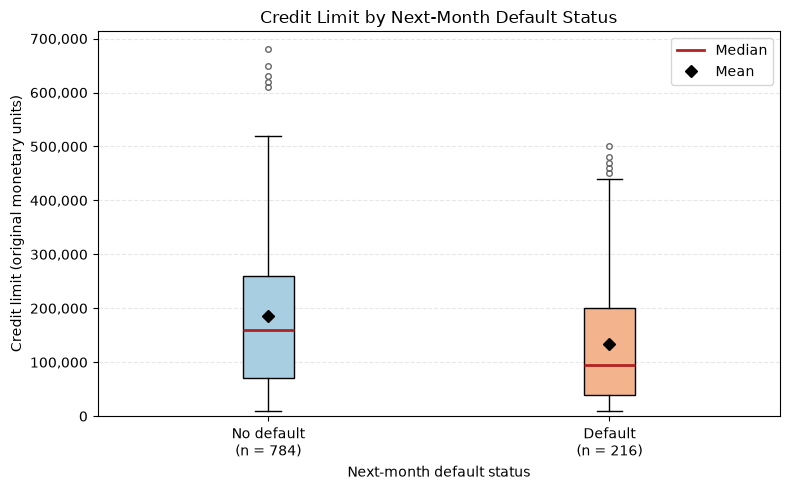

In [5]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import StrMethodFormatter

target = "default.payment.next.month"

# Select credit limits for the two groups.
non_default_limits = df.loc[df[target] == 0, "LIMIT_BAL"]
default_limits = df.loc[df[target] == 1, "LIMIT_BAL"]

# Display group statistics to support the interpretation.
credit_summary = (
    df.groupby(target)["LIMIT_BAL"]
    .agg(["count", "mean", "median", "std"])
    .reindex([0, 1])
)

credit_summary.index = ["No default", "Default"]
credit_summary.index.name = "Next-month default status"
credit_summary.columns = ["N", "Mean", "Median", "SD"]

display(
    credit_summary.style.format({
        "N": "{:.0f}",
        "Mean": "{:.4f}",
        "Median": "{:.4f}",
        "SD": "{:.4f}"
    })
)

# Create boxplots without removing extreme observations.
fig, ax = plt.subplots(figsize=(8, 5))

boxplot = ax.boxplot(
    [non_default_limits, default_limits],
    patch_artist=True,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "black",
        "markeredgecolor": "black",
        "markersize": 6
    },
    medianprops={
        "color": "#B22222",
        "linewidth": 2
    },
    flierprops={
        "marker": "o",
        "markerfacecolor": "none",
        "markeredgecolor": "#666666",
        "markersize": 4
    }
)

for box, color in zip(
    boxplot["boxes"], ["#A8CEE2", "#F2B38D"]
):
    box.set_facecolor(color)

ax.set_xticks([1, 2])
ax.set_xticklabels([
    f"No default\n(n = {len(non_default_limits)})",
    f"Default\n(n = {len(default_limits)})"
])

ax.set_title("Credit Limit by Next-Month Default Status")
ax.set_xlabel("Next-month default status")
ax.set_ylabel("Credit limit (original monetary units)")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set_ylim(bottom=0)

legend_items = [
    Line2D(
        [0], [0], color="#B22222",
        linewidth=2, label="Median"
    ),
    Line2D(
        [0], [0], marker="D", color="black",
        linestyle="None", markersize=6, label="Mean"
    )
]
ax.legend(handles=legend_items, loc="upper right")

ax.yaxis.grid(True, linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Interpretation and Business Implication

Clients who default in the next month have a lower median credit limit (95,000) than clients who do not default (160,000). The corresponding sample means are 133,657.4074 and 185,216.8367.

In both groups, the mean exceeds the median, suggesting that higher credit limits pull the average upward. The middle 50% of credit limits ranges from 40,000 to 200,000 in the default group and from 70,000 to 260,000 in the non-default group.

The distributions overlap substantially, so credit limit alone does not clearly separate clients who default from those who do not. Observations beyond the boxplot whiskers are retained; being flagged by this rule does not establish a data error.

From a business perspective, the difference motivates further investigation of how existing credit allocation relates to default outcomes. It does not imply that increasing credit limits would reduce default or that default caused credit limits to fall.

The boxplots provide descriptive evidence. A Welch two-sample t-test in Part II will assess the difference in population means, subject to the assumptions and sampling limitations discussed in the report.

#### 1.5.2 Next-Month Default Rate by Recent Repayment Status

PAY_0 records repayment status in September 2005, the most recent month of repayment history in this dataset. According to the UCI documentation, positive repayment-status codes indicate months of payment delay.

Clients are divided into two groups: PAY_0 > 0 and PAY_0 <= 0. The latter is a comparison group with no positive delay code in that month, not a group proven never to have been overdue. The brief UCI documentation does not fully explain codes -2 and 0, so no more detailed interpretation is assigned to them here.

The chart compares within-group next-month default rates. The overall sample default rate is shown as a reference.

Source: [UCI dataset documentation](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients).

,Number of clients,Number of defaults,Number of non-defaults,Default rate (%)
Recent repayment status,,,,
PAY_0 <= 0,764,106,658,13.8743
PAY_0 > 0,236,110,126,46.6102


Delay-coded minus comparison group: 32.7358 percentage points


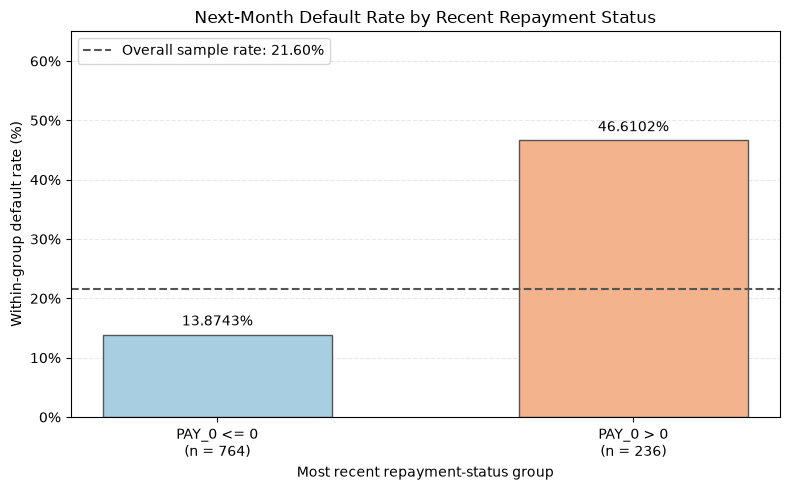

In [7]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

target = "default.payment.next.month"

# Check that the variables needed for grouping are complete.
assert df["PAY_0"].notna().all()
assert df[target].isin([0, 1]).all()

# Create a separate analysis table without changing the raw data.
delay_data = df[["PAY_0", target]].copy()
delay_data["Delay flag"] = (delay_data["PAY_0"] > 0).astype(int)

# 0 = PAY_0 <= 0; 1 = PAY_0 > 0.
delay_summary = (
    delay_data.groupby("Delay flag")[target]
    .agg(["count", "sum"])
    .reindex([0, 1])
)

delay_summary.columns = ["Number of clients", "Number of defaults"]
delay_summary["Number of non-defaults"] = (
    delay_summary["Number of clients"]
    - delay_summary["Number of defaults"]
)
delay_summary["Default rate (%)"] = (
    delay_summary["Number of defaults"]
    / delay_summary["Number of clients"]
    * 100
)

delay_summary.index = ["PAY_0 <= 0", "PAY_0 > 0"]
delay_summary.index.name = "Recent repayment status"

display(
    delay_summary.style.format({
        "Number of clients": "{:.0f}",
        "Number of defaults": "{:.0f}",
        "Number of non-defaults": "{:.0f}",
        "Default rate (%)": "{:.4f}"
    })
)

rates = delay_summary["Default rate (%)"]
overall_rate = df[target].mean() * 100

difference_pp = rates.loc["PAY_0 > 0"] - rates.loc["PAY_0 <= 0"]
print(
    f"Delay-coded minus comparison group: "
    f"{difference_pp:.4f} percentage points"
)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    [0, 1],
    rates.to_numpy(),
    width=0.55,
    color=["#A8CEE2", "#F2B38D"],
    edgecolor="#555555"
)

ax.set_xticks([0, 1])
ax.set_xticklabels([
    f"PAY_0 <= 0\n(n = {delay_summary.iloc[0]['Number of clients']:.0f})",
    f"PAY_0 > 0\n(n = {delay_summary.iloc[1]['Number of clients']:.0f})"
])

for bar, rate in zip(bars, rates):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        rate + 1,
        f"{rate:.4f}%",
        ha="center",
        va="bottom"
    )

ax.axhline(
    overall_rate,
    color="#555555",
    linestyle="--",
    label=f"Overall sample rate: {overall_rate:.2f}%"
)

ax.set_title("Next-Month Default Rate by Recent Repayment Status")
ax.set_xlabel("Most recent repayment-status group")
ax.set_ylabel("Within-group default rate (%)")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_ylim(0, 65)
ax.legend(loc="upper left")

ax.yaxis.grid(True, linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Interpretation and Business Implication

Among 236 clients with PAY_0 > 0, 110 default in the next month, giving a sample default rate of 46.6102%.Among 764 clients with PAY_0 <= 0, 106 default, giving a rate of 13.8743%.

The delay-coded group's sample default rate is higher by 32.7358 percentage points. Its rate also exceeds the overall sample default rate of 21.6%.

This pattern suggests that recent repayment delay may be useful as a warning signal for further risk assessment or customer support. However, the grouping is not a perfect classifier: 126 clients in the delay-coded group do not default, while 106 clients in the comparison group do default.

The chart provides descriptive evidence of an association. It does not establish that repayment delay causes default, and it does not evaluate predictive performance on new clients. Part II will examine the difference using a two-proportion z-test and a confidence interval.

## Part II — Research Questions and Statistical Analysis

### 2.1 Three Research Questions Proposed By The Author：

The following questions record my initial ideas before receiving
AI-generated research questions. 

**Question 1:** Does credit card default affect a customer's ability
to borrow? Do customers who default and those who do not default
have the same borrowing amount?

My initial motivation was to understand the possible borrowing
consequences of default and the importance of timely repayment.
I initially expected to use default information and borrowing amount.

**Question 2:** Is the default rate related to sex?

My initial motivation was to investigate whether differences between
groups could inform credit-limit decisions and reduce default.
I expected to use sex and default information.

**Question 3:** What is the average age of customers who default?

My initial motivation was to understand the age profile of defaulting
customers and whether age could inform credit-card issuance decisions.
I expected to use age and default information.

### 2.2 Research Questions Proposed by AI

**AI tool:** ChatGPT、Github Copilot

**Prompt:** Using the supplied DefaultCreditCard.csv dataset, propose three
business-relevant research questions that can be answered using
introductory statistical methods from my course, such as confidence
intervals, hypothesis tests, correlation, or simple linear regression.
Identify the variables and a suitable method for each question.

**AI response:**

ChatGPT

#### Question 1: What is the next-month default proportion in the population represented by this dataset?

Variable: default.payment.next.month (1 = default; 0 = no default).

Method: Calculate the sample default proportion and construct a 95% confidence interval for the population proportion. A normal-approximation interval can be used if the observed numbers of defaults and non-defaults are sufficiently large.

Business relevance: Estimating the default proportion provides a baseline measure of credit risk that can inform portfolio monitoring.

Limitation: Generalisation depends on how the supplied sample was selected and which population it represents. The estimate should not automatically be applied to all credit card customers or current market conditions.

#### Question 2: Does the mean credit limit differ between customers who default in the next month and those who do not?

Variables: LIMIT_BAL and default.payment.next.month.

Method: Use a two-sided Welch independent-samples t-test to compare the population mean credit limits of the two groups. Examine group sizes, distributions, and extreme values before interpreting the test.
$$
H_0:\mu_{\text{default}}=\mu_{\text{non-default}}
$$

$$
H_1:\mu_{\text{default}}\ne\mu_{\text{non-default}}
$$
Business relevance: This comparison can show whether existing credit limits differ between the two outcome groups and motivate further investigation of credit allocation and risk.

Limitation: LIMIT_BAL measures a credit limit, not a loan amount. A difference would indicate association; it would not establish that default caused a reduction in credit limits or that changing credit limits would change default risk. 

#### Question 3: Is there a linear association between customer age and credit limit?

Variables: AGE and LIMIT_BAL.

Method: Create a scatter plot and calculate Pearson’s correlation coefficient. A simple linear regression with credit limit as the response and age as the explanatory variable may also be used. Check whether a linear summary is reasonable and whether extreme observations strongly influence the results.

Business relevance: The analysis can describe how existing credit limits vary with age and help the bank understand the composition of its credit portfolio.

Limitation: An association does not establish that age causes differences in credit limits. Other relevant characteristics, such as income, are not included in this analysis. The findings alone would not justify age-based lending restrictions.

Github Copilot

#### Question 1: What is the default rate for this group of customers next month?

Variables：default.payment.next.month (1 = default, 0 = not default)

Method：Calculate the default rate and its confidence interval

Business relevance: Provide an estimate of the risk level of the credit portfolio.

#### Question 2: Do customers with overdue records have a higher probability of defaulting next month?

Variables：PAY_0 (current repayment status, can be grouped by whether overdue) and default.payment.next.month

Method：Compare the default rates of the two groups; conduct a two-proportion hypothesis test and report the confidence interval of the difference in proportions.

Business relevance: Determine whether the current overdue status is worthy of being regarded as a risk warning signal. We can define PAY_0 > 0 as the overdue group; this result represents an association, but not causation.

#### Question 3:Do customers with higher credit limits also have higher bill amounts?

Variables：LIMIT_BAL (Credit Limit) and BILL_AMT1 (Amount of the Latest Bill)

Method：Draw a scatter plot, calculate the Pearson correlation coefficient, and conduct simple linear regression.

Business relevance: Help to understand the relationship between the credit limit and the scale of the customer's bill, and provide a reference for credit limit management.


### 2.3 Comparison and Selection of the Final Research Questions

I compared my initial questions with the AI-generated suggestions. I selected the following three questions because they preserve my main interests and can be answered using the available variables and introductory statistical methods.

#### Final Question 1: Does the mean credit limit differ between customers who default in the next month and those who do not?

**Source:** A combination of my initial question and AI assistance.

My original question concerned borrowing amounts and the possible consequences of default. After reviewing the variables, I recognised that LIMIT_BAL measures a credit limit rather than a loan amount. The data also do not show changes in borrowing capacity after default. I therefore revised the question to compare credit limits between the two default-status groups. This revised question also matches the second AI-proposed question.

**Variables:** LIMIT_BAL and default.payment.next.month.

**Planned method:** A two-sided Welch independent-samples t-test, with a 95% confidence interval for the difference in population means. Group sizes, distributions, and extreme values will be examined.

**Business relevance:** The comparison can identify whether existing credit limits differ between the two outcome groups and motivate further investigation of credit allocation and risk. It cannot show that changing a customer's credit limit would change default risk.

#### Final Question 2: Does the next-month default proportion differ between clients with and without a positive repayment-delay code in the most recent month?

**Source:** Mainly a GitHub Copilot suggestion, selected after comparison with my original question.

My initial question compared default proportions by sex.After reviewing additional questions suggested by GitHub Copilot, I selected repayment status instead because it is more directly related to repayment behaviour and potential risk monitoring.

**Variables:** PAY_0 and default.payment.next.month.

**Planned method:** A two-sided two-proportion z-test, after checking the relevant group counts, together with a 95% confidence interval for the difference in population proportions. The difference is defined as the delay-coded group minus the comparison group.

**Business relevance:** The analysis evaluates whether recent repayment delay is associated with next-month default and may therefore warrant further investigation as a risk warning signal.
It does not establish causation or validate a predictive model.

#### Final Question 3: What is the estimated population mean age of customers who default in the next month?

**Source:** Mainly my own initial question, refined with AI assistance.

I retained my original question about the average age of defaulting customers. AI suggested adding a confidence interval to show the uncertainty associated with estimating a population mean from a sample.

**Variables:** AGE, restricted to customers for whom default.payment.next.month equals 1.

**Planned method:** Calculate the sample mean and construct a 95% one-sample t confidence interval for the population mean age of defaulting customers.

**Business relevance:** This analysis describes the age profile of defaulting customers. It does not identify which age group has the highest default risk, because that would require comparing defaults with the total number of customers in each age group. It therefore cannot justify age-based restrictions on credit cards.

#### Comparison with the Other AI Suggestions

I retained the credit-limit comparison and the mean-age question because they preserve two of my original research interests.

I replaced the sex comparison with Copilot's repayment-status question because recent repayment behaviour has a more direct connection to potential credit-risk monitoring.

The overall default proportion remains useful as a descriptive baseline in Part I, but it was not selected as a final research question. The proposed relationships between age and credit limit, and between credit limit and bill amount, are feasible but less directly aligned with my focus on default outcomes.

The questions were selected for their relevance and feasibility, rather than to obtain statistically significant results.

#### Scope of Statistical Interpretation

All three analyses use the supplied sample. Population interpretations depend on the sample being sufficiently representative and observations being independent. 

For hypothesis tests, I will use a significance level of 0.05. The analyses are exploratory, and statistical significance will not be interpreted as evidence of causation or business importance.